# Pandas

## `.Series()`

Series: ordered sequence of elements indexed by given index.
- Essentially an ordered dictionary.
- Has a single data type
- `.name()`: give a series a name
- `.values()`: returns values in the underlying array

### Indexing

Specify the index when creating a series:
```python
import pandas as pd
import numpy as np

s = pd.Series([1, 2, 3, 4], index=['a', 'b', 'c', 'd'])
print(s)
# Output:
# a    1
# b    2
# c    3
# d    4
```

Accessing index:
```python
print(s['a'])  # Output: 1
```

Use `.iloc[]` for integer-location based indexing:
```python
print(s.iloc[0, 1])  # Output: 1, 2
```

Support slicing, but upper limit inclusive

In [56]:
import numpy as np
import pandas as pd

s = pd.Series([1, 2, 3], index=["a", "b", "c"])
s["a":"c"]

a    1
b    2
c    3
dtype: int64

### Conditional selection and summary stats

In [57]:
import numpy as np
import pandas as pd

batting_averages = pd.Series(
    [20, 40, 25, 23, 27, 19, 8, 3, 42, 50, 33, 100],
    index=[
        "Broad",
        "Anderson",
        "Tongue",
        "Cook",
        "Smith",
        "Jones",
        "Williams",
        "Brown",
        "Davis",
        "Miller",
        "Wilson",
        "Bradman",
    ],
)
print(batting_averages > 30)
print("------------------------------")
print(batting_averages.median())
print(batting_averages.std())
print("------------------------------")
print(
    batting_averages[
        (batting_averages > batting_averages.median() + 2 * batting_averages.std())
        | (batting_averages < batting_averages.median() - 2 * batting_averages.std())
    ]
)

Broad       False
Anderson     True
Tongue      False
Cook        False
Smith       False
Jones       False
Williams    False
Brown       False
Davis        True
Miller       True
Wilson       True
Bradman      True
dtype: bool
------------------------------
26.0
25.217237971456964
------------------------------
Bradman    100
dtype: int64


### Modifying series

In [58]:
batting_averages = batting_averages.astype("Float64")
batting_averages.name = "Batting Averages"

batting_averages["Bradman"] = 99.94
batting_averages.iloc[-3] = 35.0
print(batting_averages, "\n----------------")

Broad        20.0
Anderson     40.0
Tongue       25.0
Cook         23.0
Smith        27.0
Jones        19.0
Williams      8.0
Brown         3.0
Davis        42.0
Miller       35.0
Wilson       33.0
Bradman     99.94
Name: Batting Averages, dtype: Float64 
----------------


## Dataframes

Table with rows and columns. Each column is a series.

In [59]:
import numpy as np
import pandas as pd

df = pd.DataFrame(
    {
        "Bowling average": ["25.3", "19.7", "30.1"],
        "Average speed": [82, 78, 89],
        "Average degrees of swing": ["1.5", "1.2", "0.7"],
    }
)
df.index = ["Anderson", "Robinson", "Wood"]
print(
    df.head(),
    "\n--------------------------------------------------------------------------------------------------",
)

print(df.columns)
print(df.index)
print(
    df.info(),
    "\n--------------------------------------------------------------------------------------------------",
)
print(df.shape)
print(df.size)
print(
    df.dtypes,
    "\n--------------------------------------------------------------------------------------------------",
)
print(df.describe())
print(df.dtypes.value_counts())


         Bowling average  Average speed Average degrees of swing
Anderson            25.3             82                      1.5
Robinson            19.7             78                      1.2
Wood                30.1             89                      0.7 
--------------------------------------------------------------------------------------------------
Index(['Bowling average', 'Average speed', 'Average degrees of swing'], dtype='str')
Index(['Anderson', 'Robinson', 'Wood'], dtype='str')
<class 'pandas.DataFrame'>
Index: 3 entries, Anderson to Wood
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Bowling average           3 non-null      str  
 1   Average speed             3 non-null      int64
 2   Average degrees of swing  3 non-null      str  
dtypes: int64(1), str(2)
memory usage: 96.0+ bytes
None 
--------------------------------------------------------------------------------------

### Indexing, selection

- `df[]`: select a column
- `df.loc[]`: select a row by label
- `df.iloc[]`: select a row by integer index

In [60]:
df.head()

,Bowling average,Average speed,Average degrees of swing
Anderson,25.3,82,1.5
Robinson,19.7,78,1.2
Wood,30.1,89,0.7


In [61]:
df["Bowling average"]

Anderson    25.3
Robinson    19.7
Wood        30.1
Name: Bowling average, dtype: str

In [62]:
df.loc["Anderson"]

Bowling average             25.3
Average speed                 82
Average degrees of swing     1.5
Name: Anderson, dtype: object

In [63]:
df.iloc[-1]

Bowling average             30.1
Average speed                 89
Average degrees of swing     0.7
Name: Wood, dtype: object

### Slicing

`,` shows that slicing x, y
or use [[`column names`]]
- End inclusive

In [64]:
print(df.loc[:, "Bowling average":"Average speed"])
print(df[["Bowling average", "Average speed"]])

         Bowling average  Average speed
Anderson            25.3             82
Robinson            19.7             78
Wood                30.1             89
         Bowling average  Average speed
Anderson            25.3             82
Robinson            19.7             78
Wood                30.1             89


### Conditional selection

In [71]:
df = df.apply(pd.to_numeric, errors="coerce")

print(
    df["Bowling average"] < 30,
    "\n--------------------------------------------------------------------------------------------------",
)
print(
    df.loc[df["Bowling average"] < 30],
    "\n--------------------------------------------------------------------------------------------------",
)
print(df.loc[df["Average speed"] > 80, ["Average speed", "Average degrees of swing"]])

Anderson     True
Robinson     True
Wood        False
Name: Bowling average, dtype: bool 
--------------------------------------------------------------------------------------------------
          Bowling average  Average speed  Average degrees of swing
Anderson             25.3             82                       1.5
Robinson             19.7             78                       1.2 
--------------------------------------------------------------------------------------------------
          Average speed  Average degrees of swing
Anderson             82                       1.5
Wood                 89                       0.7


### Dropping stuff

`.drop[]`: same logic as selection

### df/series level operations

In [85]:
s = pd.Series([7000, 84.7], index=["col1", "col2"])
df = pd.DataFrame(
    {"col1": [700, 750, 800], "col2": [100, 250, 370]}, index=["a", "b", "c"]
)
print(
    df.head(),
    "\n--------------------------------------------------------------------------------------------------",
)
print(
    s.head(),
    "\n--------------------------------------------------------------------------------------------------",
)

   col1  col2
a   700   100
b   750   250
c   800   370 
--------------------------------------------------------------------------------------------------
col1    7000.0
col2      84.7
dtype: float64 
--------------------------------------------------------------------------------------------------


In [86]:
# series/df level operation:
print(df[["col1", "col2"]] + s)

     col1   col2
a  7700.0  184.7
b  7750.0  334.7
c  7800.0  454.7


### Modifying dataframes

- `df['new_col'] = [values]`: new column
- `df['col'] = [values]`: changing values in a column
- `df.rename(columns={'old_name': 'new_name'})`: rename columns
- `df.rename(index={'old_index': 'new_index'})`: rename index

#### Creating columns from other columns

- `df['new_col'] = df['col1'] + df['col2']`: create new column by adding two columns

## Practice

In [34]:
import numpy as np
import pandas as pd

df = pd.read_csv("data/pandas_practice_market_price.csv", header=None)
df.head()

,0,1
0,2017-04-02 00:00:00,1099.169125
1,2017-04-03 00:00:00,1108.119837
2,2017-04-04 00:00:00,1107.545873
3,2017-04-05 00:00:00,1118.761201
4,2017-04-06 00:00:00,1143.106649


In [35]:
df.columns = ["Timestamp", "Price"]
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.set_index("Timestamp")
df.head()
df.tail()

,Price
Timestamp,
2018-08-10,1937.160476
2018-08-11,1946.744127
2018-08-12,1932.685434
2018-08-13,1931.330354
2018-08-14,1919.696080


In [36]:
print(df.dtypes)
print(df.shape)
print(df.info())

Price    float64
dtype: object
(500, 1)
<class 'pandas.DataFrame'>
DatetimeIndex: 500 entries, 2017-04-02 to 2018-08-14
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Price   500 non-null    float64
dtypes: float64(1)
memory usage: 7.8 KB
None


In [39]:
print(df.loc["2018-08-14"])

Price    1919.69608
Name: 2018-08-14 00:00:00, dtype: float64


### Practice Summary

1. Import data
2. Set column names
3. Convert timestamp to datetime
4. Set timestamp as index

```Python
df = pd.read_csv("data/pandas_practice_market_price.csv", header=None)
df.columns = ["Timestamp", "Price"]
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.set_index("Timestamp")
```

Can do it all within `pd.read_csv()`

In [43]:
df_faster = pd.read_csv(
    "data/pandas_practice_market_price.csv",  # import
    header=None,  # no header
    names=["Timestamp", "Price"],  # set names
    index_col=0,  # set col 0 as index
    parse_dates=True,  # parse dates: convert to datetime
)
df_faster.head()

,Price
Timestamp,
2017-04-02,1099.169125
2017-04-03,1108.119837
2017-04-04,1107.545873
2017-04-05,1118.761201
2017-04-06,1143.106649


### Plotting basics

Pandas integrated with Mapplotlib: `.plot()`

<Axes: xlabel='Timestamp'>

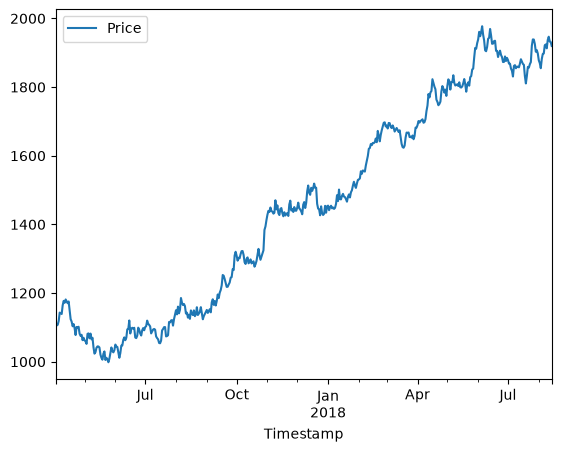

In [44]:
df_faster.plot()

<Axes: title={'center': 'January 2018 Market Price'}, xlabel='Timestamp'>

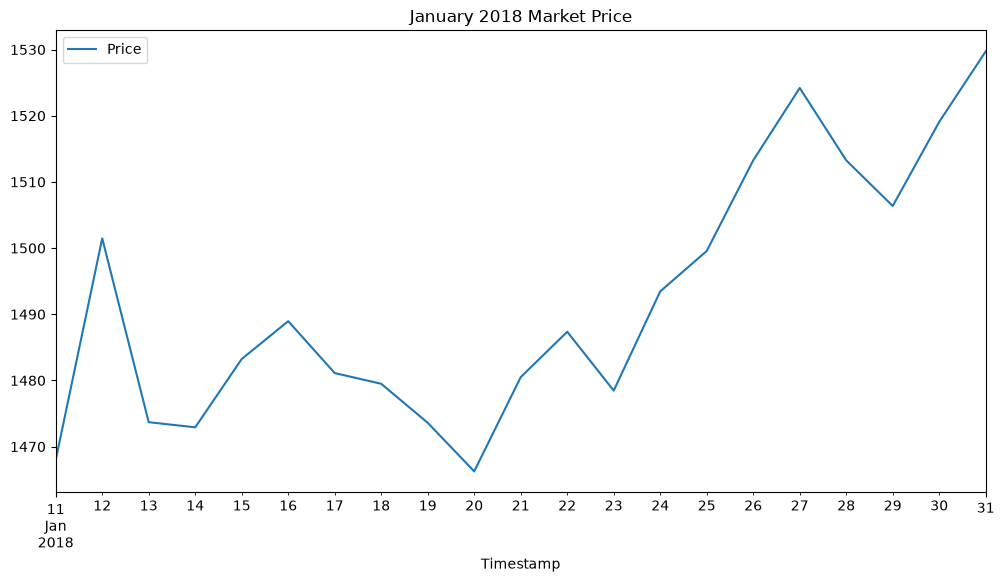

In [52]:
df_faster.loc["2018-01-11":"2018-01-31"].plot(
    figsize=(12, 6), title="January 2018 Market Price"
)